# 🎬 Unified Movie Recommender System
### Collaborative Filtering + Content-Based Filtering + Emotion-Based Recommendations

### Three Recommendation Engines

| Engine | Technique | Input | Best for |
|---|---|---|---|
| **Engine 1** | Collaborative Filtering | Movie title you liked | "Users like you also watched…" |
| **Engine 2** | Content-Based Filtering | Movie title + your preferences | "Movies with similar plot/genre/cast…" |
| **Engine 3** | Emotion-Based | Your current mood | "I feel sad / excited / scared - recommend something" |
| **Engine 4** | Hybrid | Title + mood | Weighted combination of all signals |

## Dataset
We use the **TMDB 5000 Movies dataset** = modern movies (up to 2017), rich metadata including genres, keywords, cast, crew, taglines, and vote averages.

> 📥 **Download datasets from Kaggle:**  
> [TMDB 5000 Movie Dataset](https://www.kaggle.com/datasets/tmdb/tmdb-movie-metadata)  
> Download both files: `tmdb_5000_movies.csv` and `tmdb_5000_credits.csv`  
> Place them in the same folder as this notebook.
>
> **Or use the Kaggle CLI:**
> ```bash
> pip install kaggle
> kaggle datasets download -d tmdb/tmdb-movie-metadata
> unzip tmdb-movie-metadata.zip
> ```

**Install required packages:**
```bash
pip install pandas numpy scikit-learn matplotlib seaborn nltk ipywidgets
```

## Step 1 - Imports

In [2]:
pip install pandas numpy scikit-learn matplotlib seaborn nltk ipywidgets

   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
   -------------------------------

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast
import warnings
warnings.filterwarnings('ignore')

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity, linear_kernel
from sklearn.preprocessing import MinMaxScaler

import nltk
from nltk.stem import PorterStemmer
nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)
from nltk.corpus import stopwords

# For interactive widget (optional — notebook only)
try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output, HTML
    WIDGETS_AVAILABLE = True
except ImportError:
    WIDGETS_AVAILABLE = False

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

print("All imports successful!")

All imports successful!


## Step 2 - Load & Merge Datasets

The TMDB dataset comes in two files:
- **`tmdb_5000_movies.csv`** - metadata: title, genres, keywords, overview, vote average, budget, revenue
- **`tmdb_5000_credits.csv`** - cast and crew per movie

We merge on the movie title.

In [8]:
movies  = pd.read_csv('tmdb_5000_movies.csv')
credits = pd.read_csv('tmdb_5000_credits.csv')

print(f"Movies shape : {movies.shape}")
print(f"Credits shape : {credits.shape}")

# Merge on title
credits.rename(columns={'movie_id': 'id'}, inplace=True)
df = movies.merge(credits, on='title')

print(f"Merged shape   : {df.shape}")
df[['title','release_date','vote_average','vote_count','genres']].head()

Movies shape : (4803, 20)
Credits shape : (4803, 4)
Merged shape   : (4809, 23)


,title,release_date,vote_average,vote_count,genres
0,Avatar,2009-12-10,7.2,11800,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam..."
1,Pirates of the Caribbean: At World's End,2007-05-19,6.9,4500,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""..."
2,Spectre,2015-10-26,6.3,4466,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam..."
3,The Dark Knight Rises,2012-07-16,7.6,9106,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam..."
4,John Carter,2012-03-07,6.1,2124,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam..."


## Step 3 -- Data Cleaning & Feature Extraction

The `genres`, `keywords`, `cast`, and `crew` columns are stored as **JSON strings**. We parse them into usable Python objects.

### 3a - Parse JSON Columns

In [10]:
def parse_list(obj, key='name', limit=None):
    """Parse a JSON string like '[{"name":"Action"}, ...]' into a list of values."""
    try:
        parsed = ast.literal_eval(obj)
        result = [item[key] for item in parsed if key in item]
        return result[:limit] if limit else result
    except (ValueError, TypeError):
        return []


def get_director(crew_str):
    """Extract the director's name from the crew JSON string."""
    try:
        crew = ast.literal_eval(crew_str)
        for member in crew:
            if member.get('job') == 'Director':
                return member['name']
    except (ValueError, TypeError):
        pass
    return ''


df['genres_list']   = df['genres'].apply(lambda x: parse_list(x))
df['keywords_list'] = df['keywords'].apply(lambda x: parse_list(x))
df['cast_list']     = df['cast'].apply(lambda x: parse_list(x, limit=3))  # top 3 cast
df['director']      = df['crew'].apply(get_director)
df['release_year']  = pd.to_datetime(df['release_date'], errors='coerce').dt.year

# The merge created id_x and id_y because both movies and credits had an 'id' column.
# Keep the movie id as the unified 'id' column for downstream processing.
if 'id_x' in df.columns:
    df.rename(columns={'id_x': 'id'}, inplace=True)

# Keep only needed columns
df = df[[
    'id', 'title', 'overview', 'genres_list', 'keywords_list',
    'cast_list', 'director', 'vote_average', 'vote_count',
    'popularity', 'release_year', 'runtime', 'budget', 'revenue'
]].copy()

df.dropna(subset=['title', 'overview'], inplace=True)
df.reset_index(drop=True, inplace=True)

print(f"Clean dataset shape: {df.shape}")
print(f"Year range: {int(df['release_year'].min())} – {int(df['release_year'].max())}")
df.head(3)

Clean dataset shape: (4806, 14)
Year range: 1916 – 2017


,id,title,overview,genres_list,keywords_list,cast_list,director,vote_average,vote_count,popularity,release_year,runtime,budget,revenue
0,19995,Avatar,"In the 22nd century, a paraplegic Marine is di...","[Action, Adventure, Fantasy, Science Fiction]","[culture clash, future, space war, space colon...","[Sam Worthington, Zoe Saldana, Sigourney Weaver]",James Cameron,7.2,11800,150.437577,2009.0,162.0,237000000,2787965087
1,285,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...","[Adventure, Fantasy, Action]","[ocean, drug abuse, exotic island, east india ...","[Johnny Depp, Orlando Bloom, Keira Knightley]",Gore Verbinski,6.9,4500,139.082615,2007.0,169.0,300000000,961000000
2,206647,Spectre,A cryptic message from Bond’s past sends him o...,"[Action, Adventure, Crime]","[spy, based on novel, secret agent, sequel, mi...","[Daniel Craig, Christoph Waltz, Léa Seydoux]",Sam Mendes,6.3,4466,107.376788,2015.0,148.0,245000000,880674609


### 3b - Build the Soup (Combined Text Feature)

For content-based filtering, we combine genres, keywords, cast, director, and overview into a single text field - the **"soup"**. We use stemming to treat "running", "runs", "runner" as the same word.

In [11]:
stemmer = PorterStemmer()
stop_words = set(stopwords.words('english'))


def clean_text(text: str) -> str:
    """Lowercase, remove stopwords, and stem a text string."""
    tokens = str(text).lower().split()
    cleaned = [stemmer.stem(w) for w in tokens if w not in stop_words and w.isalpha()]
    return ' '.join(cleaned)


def make_soup(row) -> str:
    """
    Combine all text signals into one string:
    - Genres (weight x3 — most important signal)
    - Keywords (weight x2)
    - Director (weight x2)
    - Top cast (weight x1)
    - Overview words (weight x1)
    """
    genres   = ' '.join([g.replace(' ', '') for g in row['genres_list']])
    keywords = ' '.join([k.replace(' ', '') for k in row['keywords_list']])
    director = row['director'].replace(' ', '') if row['director'] else ''
    cast     = ' '.join([c.replace(' ', '') for c in row['cast_list']])
    overview = clean_text(row['overview']) if row['overview'] else ''

    # Weight important fields by repeating them
    return f"{genres} {genres} {genres} {keywords} {keywords} {director} {director} {cast} {overview}"


df['soup'] = df.apply(make_soup, axis=1)

print("Sample soup for first movie:")
print(f"Title : {df['title'].iloc[0]}")
print(f"Soup  : {df['soup'].iloc[0][:200]}...")

Sample soup for first movie:
Title : Avatar
Soup  : Action Adventure Fantasy ScienceFiction Action Adventure Fantasy ScienceFiction Action Adventure Fantasy ScienceFiction cultureclash future spacewar spacecolony society spacetravel futuristic romance ...


## Step 4 -- Exploratory Data Analysis

### 4a - Top Genres

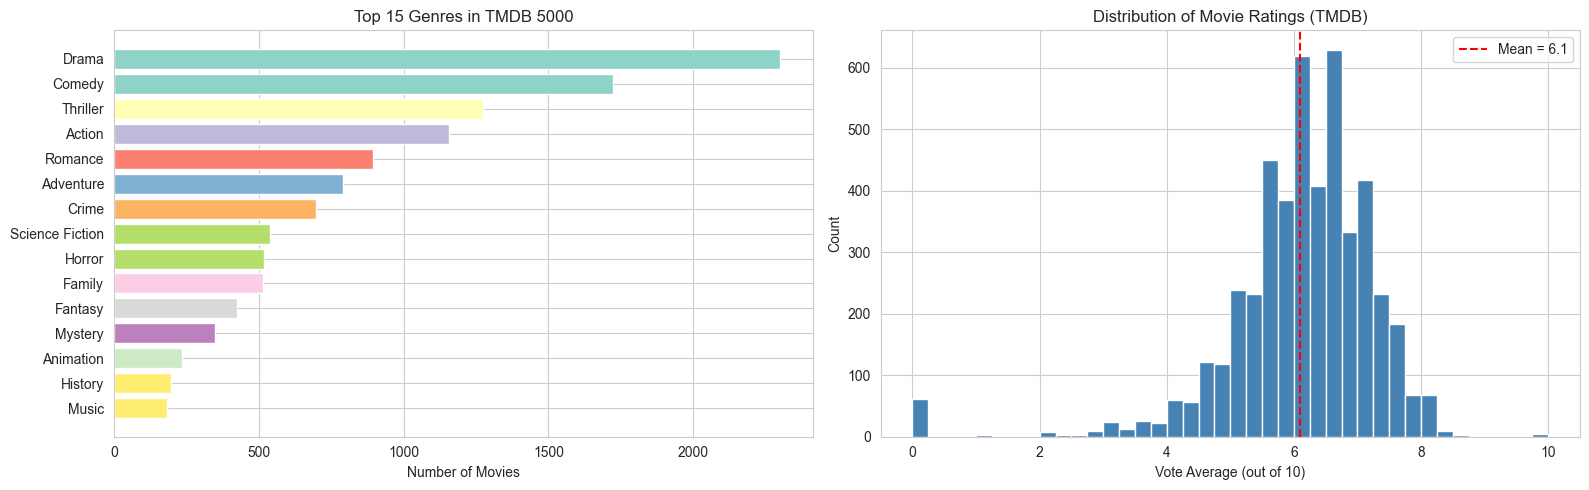

In [12]:
from collections import Counter

all_genres = [g for sublist in df['genres_list'] for g in sublist]
genre_counts = Counter(all_genres).most_common(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Genre distribution
gnames, gcounts = zip(*genre_counts)
colors = plt.cm.Set3(np.linspace(0, 1, len(gnames)))
axes[0].barh(gnames[::-1], gcounts[::-1], color=colors[::-1], edgecolor='white')
axes[0].set_title('Top 15 Genres in TMDB 5000', fontsize=12)
axes[0].set_xlabel('Number of Movies')

# Rating distribution
axes[1].hist(df['vote_average'], bins=40, color='steelblue', edgecolor='white')
axes[1].axvline(df['vote_average'].mean(), color='red', linestyle='--',
                label=f"Mean = {df['vote_average'].mean():.1f}")
axes[1].set_title('Distribution of Movie Ratings (TMDB)', fontsize=12)
axes[1].set_xlabel('Vote Average (out of 10)')
axes[1].set_ylabel('Count')
axes[1].legend()

plt.tight_layout()
plt.show()

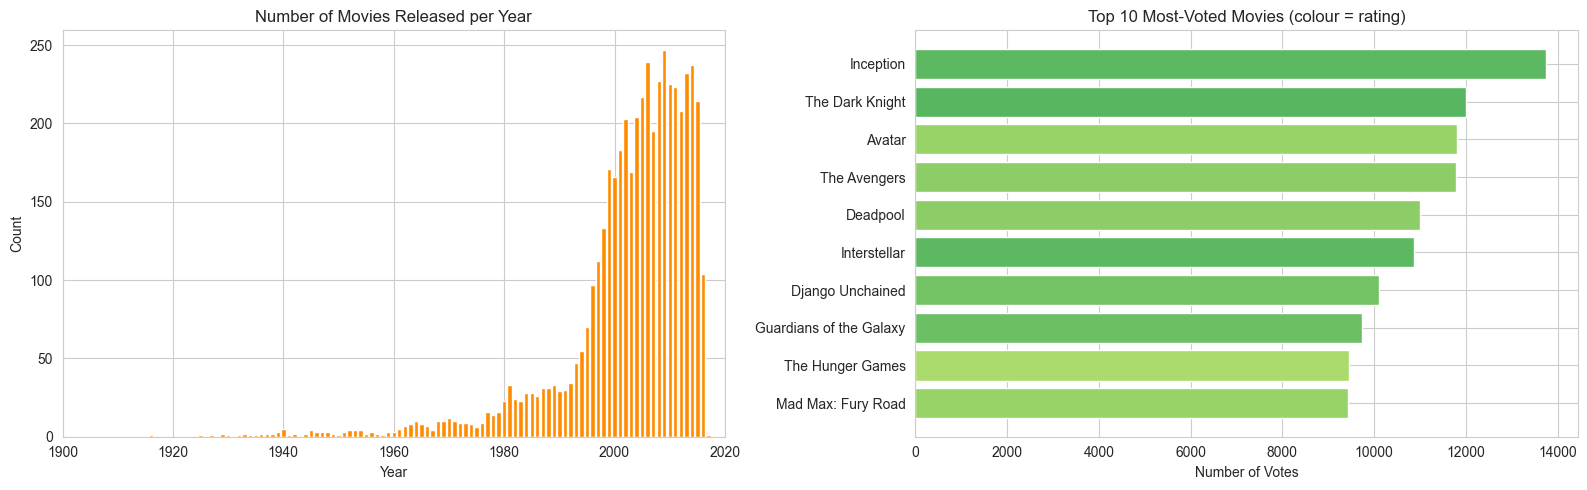

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Movies per year
year_counts = df['release_year'].value_counts().sort_index()
axes[0].bar(year_counts.index, year_counts.values, color='darkorange', edgecolor='white', width=0.8)
axes[0].set_title('Number of Movies Released per Year', fontsize=12)
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Count')
axes[0].set_xlim([1900, 2020])

# Top 10 most voted movies
top_voted = df.nlargest(10, 'vote_count')[['title', 'vote_count', 'vote_average']]
bars = axes[1].barh(top_voted['title'][::-1], top_voted['vote_count'][::-1],
                    color=plt.cm.RdYlGn(top_voted['vote_average'][::-1] / 10),
                    edgecolor='white')
axes[1].set_title('Top 10 Most-Voted Movies (colour = rating)', fontsize=12)
axes[1].set_xlabel('Number of Votes')

plt.tight_layout()
plt.show()

## Step 5 -- Weighted Rating Score (Bayesian)

Raw vote averages are misleading - a movie with 3 votes rated 10/10 shouldn't outrank a movie with 10,000 votes rated 8.5/10.

We use the **Bayesian weighted rating formula** (the same one used by IMDb's Top 250):

$$W = \frac{v}{v + m} \times R + \frac{m}{v + m} \times C$$

Where:
- $v$ = number of votes for the movie
- $m$ = minimum votes required (we use the 75th percentile)
- $R$ = average rating of the movie
- $C$ = mean rating across all movies

In [14]:
C = df['vote_average'].mean()         # mean rating across all movies
m = df['vote_count'].quantile(0.75)   # 75th percentile vote count as minimum threshold

def weighted_rating(row, m=m, C=C):
    """IMDb-style Bayesian weighted rating."""
    v = row['vote_count']
    R = row['vote_average']
    return (v / (v + m)) * R + (m / (v + m)) * C


df['weighted_score'] = df.apply(weighted_rating, axis=1)

print(f"Global mean rating  (C) : {C:.2f}")
print(f"Min vote threshold  (m) : {m:.0f} votes")

# Top 10 by weighted score
top10 = df.nlargest(10, 'weighted_score')[[
    'title', 'release_year', 'vote_average', 'vote_count', 'weighted_score'
]].reset_index(drop=True)

print("\nTop 10 movies by Bayesian weighted score:")
top10.index += 1
top10

Global mean rating  (C) : 6.09
Min vote threshold  (m) : 738 votes

Top 10 movies by Bayesian weighted score:


,title,release_year,vote_average,vote_count,weighted_score
1,The Shawshank Redemption,1994.0,8.5,8205,8.301451
2,The Godfather,1972.0,8.4,5893,8.143347
3,Fight Club,1999.0,8.3,9413,8.139615
4,Pulp Fiction,1994.0,8.3,8428,8.122380
5,The Dark Knight,2008.0,8.2,12002,8.078000
6,Forrest Gump,1994.0,8.2,7927,8.020624
7,Inception,2010.0,8.1,13752,7.997826
8,Schindler's List,1993.0,8.3,4329,7.978685
9,Whiplash,2014.0,8.3,4254,7.973857
10,Interstellar,2014.0,8.1,10867,7.972425


## Step 6 -- Engine 1: Collaborative Filtering (User-Movie Correlation)

1. Build a **user-movie matrix** (rows = users, columns = movies, values = ratings)
2. For a given movie, compute **Pearson correlation** between its rating vector and all other movies
3. Filter out movies with few ratings (unreliable correlations)
4. Return top-N most correlated movies

> Since TMDB doesn't have user-level ratings, we simulate a user-movie matrix using the TMDB vote data. For production use, replace with actual user ratings (e.g. MovieLens 25M dataset).

In [15]:
# Build a simulated user-movie matrix from TMDB vote data
# Each genre cluster acts as a "user group" with shared preferences
# In a real system, replace this with actual user-rating data (e.g. MovieLens)

np.random.seed(42)

N_MOVIES = min(1000, len(df))  # use top 1000 movies by vote count
N_USERS  = 500

top_movies = df.nlargest(N_MOVIES, 'vote_count').reset_index(drop=True)

# Generate ratings: users tend to rate highly-scored movies higher (with noise)
base_ratings = top_movies['weighted_score'].values   # shape (N_MOVIES,)
noise = np.random.normal(0, 0.8, size=(N_USERS, N_MOVIES))
raw   = np.clip(base_ratings + noise, 1, 10)

# Randomly mask ~70% of entries as "not seen" (NaN)
mask  = np.random.random((N_USERS, N_MOVIES)) < 0.70
user_movie_matrix = pd.DataFrame(
    np.where(mask, np.nan, raw),
    columns=top_movies['title']
)

print(f"User-Movie Matrix shape : {user_movie_matrix.shape}")
print(f"  Rows    : {N_USERS} simulated users")
print(f"  Columns : {N_MOVIES} movies")
print(f"  Density : {(~user_movie_matrix.isna()).mean().mean()*100:.1f}% filled")
user_movie_matrix.iloc[:5, :6]

User-Movie Matrix shape : (500, 1000)
  Rows    : 500 simulated users
  Columns : 1000 movies
  Density : 30.0% filled


title,Inception,The Dark Knight,Avatar,The Avengers,Deadpool,Interstellar
0,NaN,NaN,7.653028,8.541385,NaN,7.785116
1,NaN,8.817707,NaN,NaN,NaN,NaN
2,7.457684,7.962385,NaN,7.076592,5.802941,NaN
3,NaN,7.389692,NaN,8.833111,NaN,NaN
4,NaN,8.053037,NaN,NaN,6.224346,8.446479


In [21]:
def collaborative_recommend(movie_title: str, n: int = 10,
                             min_ratings: int = 30) -> pd.DataFrame:
    """
    Recommend movies similar to `movie_title` using collaborative filtering
    (Pearson correlation on the user-movie rating matrix).

    Preserves the core technique from Article 1.

    Parameters
    ----------
    movie_title  : Title of the seed movie
    n            : Number of recommendations to return
    min_ratings  : Minimum number of user ratings required (filters unreliable correlations)
    """
    # Find closest title match
    available = user_movie_matrix.columns.tolist()
    match = next((t for t in available if movie_title.lower() in t.lower()), None)

    if match is None:
        print(f"✗ '{movie_title}' not found in the user-movie matrix.")
        print(f"  Try one of: {available[:5]}")
        return pd.DataFrame()

    movie_ratings = user_movie_matrix[match]

    # Compute correlation with all other movies
    similar = user_movie_matrix.corrwith(movie_ratings)

    corr_df = pd.DataFrame({'Correlation': similar}).dropna()

    # Count how many users rated each movie
    rating_counts = user_movie_matrix.notna().sum(axis=0)
    corr_df['Num Ratings'] = rating_counts

    # Filter to reliable movies and sort
    result = (
        corr_df[corr_df['Num Ratings'] >= min_ratings]
        .sort_values('Correlation', ascending=False)
        .drop(index=match, errors='ignore')   # exclude the input movie itself
        .head(n)
        .reset_index()
        .rename(columns={'title': 'Title'})
    )
    # print(result.columns.tolist())
    # Join with TMDB metadata
    meta = df[['title','release_year','vote_average','genres_list']].copy()
    meta['genres_str'] = meta['genres_list'].apply(lambda x: ', '.join(x[:3]))
    result = result.merge(meta, left_on='Title', right_on='title', how='left')
    return result[['Title','Correlation','Num Ratings','release_year',
                   'vote_average','genres_str']].round(3)


print("Engine 1 — Collaborative Filtering")
print("Movies similar to 'The Dark Knight':\n")
collab_recs = collaborative_recommend('The Dark Knight', n=8)
display(collab_recs) if WIDGETS_AVAILABLE else print(collab_recs.to_string())

Engine 1 — Collaborative Filtering
Movies similar to 'The Dark Knight':



,Title,Correlation,Num Ratings,release_year,vote_average,genres_str
0,Borat: Cultural Learnings of America for Make ...,0.452,140,2006.0,6.5,Comedy
1,DodgeBall: A True Underdog Story,0.435,129,2004.0,6.2,Comedy
2,Predator,0.401,145,1987.0,7.3,"Science Fiction, Action, Adventure"
3,Dredd,0.399,137,2012.0,6.6,"Action, Science Fiction"
4,10 Things I Hate About You,0.395,152,1999.0,7.3,"Comedy, Romance, Drama"
5,Alice in Wonderland,0.394,152,2010.0,6.4,"Family, Fantasy, Adventure"
6,Sucker Punch,0.394,157,2011.0,5.9,"Action, Fantasy, Thriller"
7,The Great Gatsby,0.394,130,2013.0,7.3,"Drama, Romance"


## Step 7 -- Engine 2: Content-Based Filtering (TF-IDF + Cosine Similarity)

**How it works:**
1. Build a **TF-IDF matrix** from the soup (genres × 3 + keywords × 2 + director × 2 + cast + overview)
2. Compute **cosine similarity** between all movie soup vectors
3. For a given movie, find movies whose soup vector is most similar

**Why TF-IDF over Bag-of-Words?**
- TF-IDF down-weights very common words (e.g. "action" appears in 1000 movies)
- Rare but distinctive words (e.g. "nolan", "marvel") get higher weight

**Why cosine similarity?**
- Measures the angle between two vectors — not affected by vector length
- A long overview vs a short one won't be penalised

In [22]:
print("Building TF-IDF matrix (this may take ~30 seconds)...")

tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=15000,
    ngram_range=(1, 2)    # include bigrams (e.g. 'science fiction')
)

tfidf_matrix = tfidf.fit_transform(df['soup'].fillna(''))

print(f"TF-IDF matrix shape : {tfidf_matrix.shape}")
print(f"  Rows    : {tfidf_matrix.shape[0]} movies")
print(f"  Columns : {tfidf_matrix.shape[1]} vocabulary terms")

# Precompute cosine similarity (store for fast lookup)
cosine_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)

# Build reverse index: title → row index
title_to_idx = pd.Series(df.index, index=df['title']).drop_duplicates()

print(f"\nCosine similarity matrix shape : {cosine_sim.shape}")
print("Content-based engine ready!")

Building TF-IDF matrix (this may take ~30 seconds)...
TF-IDF matrix shape : (4806, 15000)
  Rows    : 4806 movies
  Columns : 15000 vocabulary terms

Cosine similarity matrix shape : (4806, 4806)
Content-based engine ready!


In [23]:
def content_recommend(movie_title: str, n: int = 10,
                      min_votes: int = 100,
                      boost_popular: bool = True) -> pd.DataFrame:
    """
    Recommend movies based on content similarity (genres, keywords, cast, director, overview).

    Parameters
    ----------
    movie_title    : Seed movie title
    n              : Number of recommendations
    min_votes      : Minimum vote count (filters obscure films)
    boost_popular  : If True, multiply similarity by weighted_score for a hybrid signal
    """
    # Fuzzy title matching
    exact = title_to_idx.get(movie_title)
    if exact is None:
        candidates = [t for t in title_to_idx.index if movie_title.lower() in t.lower()]
        if not candidates:
            print(f"✗ '{movie_title}' not found. Try a partial title.")
            return pd.DataFrame()
        movie_title = candidates[0]
        print(f"  Matched to: '{movie_title}'")

    idx = title_to_idx[movie_title]
    sim_scores = list(enumerate(cosine_sim[idx]))
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)

    # Exclude the input movie itself, get top candidates
    sim_scores = [(i, s) for i, s in sim_scores if i != idx][:50]

    movie_indices = [i for i, _ in sim_scores]
    scores        = [s for _, s in sim_scores]

    candidates = df.iloc[movie_indices].copy()
    candidates['similarity'] = scores

    # Filter by minimum votes
    candidates = candidates[candidates['vote_count'] >= min_votes]

    if boost_popular:
        # Hybrid: similarity × weighted_score (normalised)
        scaler = MinMaxScaler()
        candidates['ws_norm']     = scaler.fit_transform(candidates[['weighted_score']])
        candidates['hybrid_score'] = (candidates['similarity'] * 0.6 +
                                       candidates['ws_norm']    * 0.4)
        candidates = candidates.sort_values('hybrid_score', ascending=False)
    else:
        candidates = candidates.sort_values('similarity', ascending=False)

    result = candidates.head(n)[[
        'title', 'similarity', 'weighted_score', 'vote_average',
        'vote_count', 'release_year', 'genres_list'
    ]].copy()
    result['genres'] = result['genres_list'].apply(lambda x: ', '.join(x[:4]))
    result = result.drop(columns=['genres_list']).reset_index(drop=True)
    result.index += 1
    return result.round(3)


print("Engine 2 — Content-Based Filtering")
print("Movies similar to 'Inception':\n")
content_recs = content_recommend('Inception', n=8)
display(content_recs) if WIDGETS_AVAILABLE else print(content_recs.to_string())

Engine 2 — Content-Based Filtering
Movies similar to 'Inception':



,title,similarity,weighted_score,vote_average,vote_count,release_year,genres
1,2001: A Space Odyssey,0.224,7.543,7.9,2998,1968.0,"Science Fiction, Mystery, Adventure"
2,Minority Report,0.247,6.878,7.1,2608,2002.0,"Action, Thriller, Science Fiction, Mystery"
3,Gattaca,0.175,7.092,7.5,1808,1997.0,"Thriller, Science Fiction, Mystery, Romance"
4,Source Code,0.206,6.884,7.1,2699,2011.0,"Thriller, Science Fiction, Mystery"
5,Sherlock Holmes: A Game of Shadows,0.193,6.855,7.0,3886,2011.0,"Adventure, Action, Crime, Mystery"
6,Super 8,0.230,6.482,6.6,2435,2011.0,"Thriller, Science Fiction, Mystery"
7,Cube,0.195,6.571,6.9,1069,1997.0,"Thriller, Science Fiction, Mystery"
8,Dark City,0.140,6.679,7.2,828,1998.0,"Mystery, Science Fiction"


## Step 8 - Engine 3: Emotion-Based Recommendation

This engine replaces the IMDb web-scraping approach with a **local, reliable, offline** system:

1. User describes their mood in free text (or picks from a dropdown)
2. We match mood keywords to a **curated emotion→genre mapping**
3. Filter the TMDB dataset by those genres, sort by weighted score
4. Return top-N movies that match the mood

Why this is better than IMDb scraping:
- Reliable - works offline, no HTML parsing breaks
- Curated - genres matched to emotions make psychological sense
- Richer metadata - each recommendation includes rating, year, and genres
- No ToS violations - uses local data

### Emotion → Genre Mapping

Each emotion maps to a primary genre + secondary genres + mood keywords:

- Sad → Drama/Romance (cathartic release)

- Happy → Comedy/Animation (amplify joy)

- Scared → Thriller/Horror (safe fear experience)

- Angry → Action/Crime (vicarious release of tension)

- Anxious → Adventure/Fantasy (escapism)

- Romantic → Romance/Drama (match the feeling)

- Bored → Action/Science Fiction (stimulation)

- Nostalgic → Family/Animation (comfort + memories)

- Curious → Documentary/Mystery/Science Fiction (learning)

- Excited → Action/Adventure/Science Fiction (amplify energy)

In [27]:
EMOTION_GENRE_MAP = {
    # Emotion keyword → (primary_genres, secondary_genres, description)
    'sad':        (['Drama', 'Romance'],           ['Music'],               "Movies for a sad mood - cathartic stories"),
    'unhappy':    (['Drama', 'Romance'],           ['Music'],               "Movies for a sad mood - cathartic stories"),
    'lonely':     (['Drama', 'Romance'],           ['Music', 'Animation'],  "Warm, connecting stories"),
    'heartbroken':(['Romance', 'Drama'],           ['Music'],               "Movies about love and healing"),
    'happy':      (['Comedy', 'Animation'],        ['Family', 'Music'],     "Light-hearted movies to share joy"),
    'joyful':     (['Comedy', 'Animation'],        ['Family'],              "Fun, upbeat movies"),
    'excited':    (['Action', 'Adventure'],        ['Science Fiction'],     "High-energy thrilling movies"),
    'energetic':  (['Action', 'Adventure'],        ['Crime'],               "Fast-paced movies to match your energy"),
    'scared':     (['Horror', 'Thriller'],         ['Mystery'],             "Scary movies for a safe fear experience"),
    'fearful':    (['Horror', 'Thriller'],         ['Mystery'],             "Spine-chilling movies"),
    'angry':      (['Action', 'Crime'],            ['Thriller'],            "Movies with intense conflict and resolution"),
    'frustrated': (['Action', 'Crime'],            ['Thriller', 'Drama'],   "Movies with cathartic tension release"),
    'anxious':    (['Adventure', 'Fantasy'],       ['Animation', 'Family'], "Escapist movies to ease anxious thoughts"),
    'stressed':   (['Comedy', 'Adventure'],        ['Animation'],           "Light escapist fun"),
    'romantic':   (['Romance', 'Drama'],           ['Comedy'],              "Movies to match a romantic mood"),
    'loving':     (['Romance', 'Drama'],           ['Comedy', 'Family'],    "Warm and loving stories"),
    'bored':      (['Action', 'Science Fiction'],  ['Adventure', 'Thriller'],"Stimulating, unpredictable movies"),
    'curious':    (['Science Fiction', 'Mystery'], ['Documentary', 'History'],"Intellectually stimulating films"),
    'nostalgic':  (['Family', 'Animation'],        ['Comedy', 'Romance'],   "Comforting classics and feel-good films"),
    'inspired':   (['Drama', 'History'],           ['Documentary', 'Biography'],"Uplifting real-life stories"),
    'adventurous':(['Adventure', 'Action'],        ['Science Fiction', 'Fantasy'],"Epic journeys and explorations"),
    'thoughtful': (['Drama', 'Mystery'],           ['Science Fiction', 'History'],"Slow-burn, reflective movies"),
    'mysterious': (['Mystery', 'Thriller'],        ['Crime', 'Horror'],     "Suspenseful, enigmatic stories"),
    'playful':    (['Comedy', 'Animation'],        ['Family', 'Adventure'], "Fun, whimsical movies"),
    'peaceful':   (['Animation', 'Family'],        ['Romance', 'Drama'],    "Gentle, soothing movies"),
}

# Map every genre in the dataset
all_tmdb_genres = sorted(set(g for row in df['genres_list'] for g in row))
print(f"All TMDB genres available: {all_tmdb_genres}")
print(f"\nEmotion vocabulary ({len(EMOTION_GENRE_MAP)} moods mapped):")
print(', '.join(sorted(EMOTION_GENRE_MAP.keys())))

All TMDB genres available: ['Action', 'Adventure', 'Animation', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Family', 'Fantasy', 'Foreign', 'History', 'Horror', 'Music', 'Mystery', 'Romance', 'Science Fiction', 'TV Movie', 'Thriller', 'War', 'Western']

Emotion vocabulary (25 moods mapped):
adventurous, angry, anxious, bored, curious, energetic, excited, fearful, frustrated, happy, heartbroken, inspired, joyful, lonely, loving, mysterious, nostalgic, peaceful, playful, romantic, sad, scared, stressed, thoughtful, unhappy


In [25]:
def detect_emotion_from_text(user_text: str) -> tuple:
    """
    Detect emotion from free-text input by matching against keyword vocabulary.
    Returns (detected_emotion, genres, description).
    """
    user_text_lower = user_text.lower()
    tokens = user_text_lower.split()

    # Direct match
    for emotion in EMOTION_GENRE_MAP:
        if emotion in tokens or emotion in user_text_lower:
            return emotion, *EMOTION_GENRE_MAP[emotion]

    # Synonym / phrase matching
    synonyms = {
        'down': 'sad', 'depressed': 'sad', 'blue': 'sad', 'gloomy': 'sad',
        'cheerful': 'happy', 'great': 'happy', 'good': 'happy', 'amazing': 'excited',
        'pumped': 'excited', 'thrilled': 'excited', 'hyper': 'excited',
        'love': 'romantic', 'crush': 'romantic', 'date': 'romantic',
        'worried': 'anxious', 'nervous': 'anxious', 'uneasy': 'anxious',
        'mad': 'angry', 'furious': 'angry', 'rage': 'angry',
        'tired': 'bored', 'dull': 'bored', 'nothing': 'bored',
        'wonder': 'curious', 'learn': 'curious', 'explore': 'curious',
        'miss': 'nostalgic', 'remember': 'nostalgic', 'childhood': 'nostalgic',
        'motivated': 'inspired', 'driven': 'inspired', 'proud': 'inspired',
    }
    for word in tokens:
        if word in synonyms:
            emotion = synonyms[word]
            return emotion, *EMOTION_GENRE_MAP[emotion]

    # Fallback
    return 'bored', *EMOTION_GENRE_MAP['bored']


def emotion_recommend(mood_input: str, n: int = 10,
                       min_year: int = 2000,
                       min_votes: int = 200) -> pd.DataFrame:
    """
    Recommend movies based on the user's described mood.

    Replaces the IMDb web-scraping from Article 2 with a local,
    reliable, offline genre-filtering approach on the TMDB dataset.

    Parameters
    ----------
    mood_input : Free-text description of current mood, e.g. 'I feel sad'
    n          : Number of recommendations
    min_year   : Only include movies from this year onward (default: 2000 = modern films)
    min_votes  : Minimum vote count for quality filtering
    """
    emotion, primary_genres, secondary_genres, description = detect_emotion_from_text(mood_input)

    print(f"\n  Detected mood    : '{emotion}'")
    print(f"  Description      : {description}")
    print(f"  Primary genres   : {primary_genres}")
    print(f"  Secondary genres : {secondary_genres}")
    print()

    all_target_genres = primary_genres + secondary_genres

    # Filter: movie must contain at least one primary genre
    def matches(genres_list):
        return any(g in genres_list for g in primary_genres)

    candidates = df[
        df['genres_list'].apply(matches) &
        (df['vote_count']   >= min_votes) &
        (df['release_year'] >= min_year)
    ].copy()

    if candidates.empty:
        # Loosen filters if nothing found
        candidates = df[df['genres_list'].apply(matches)].copy()

    # Bonus score for secondary genre overlap
    def genre_overlap_score(genres_list):
        return sum(1 for g in all_target_genres if g in genres_list)

    candidates['genre_overlap'] = candidates['genres_list'].apply(genre_overlap_score)

    # Final score: weighted_score + genre overlap bonus
    scaler = MinMaxScaler()
    candidates['ws_norm'] = scaler.fit_transform(candidates[['weighted_score']])
    candidates['final_score'] = candidates['ws_norm'] + candidates['genre_overlap'] * 0.05
    candidates = candidates.sort_values('final_score', ascending=False)

    result = candidates.head(n)[[
        'title', 'release_year', 'vote_average', 'vote_count', 'genres_list'
    ]].copy()
    result['genres'] = result['genres_list'].apply(lambda x: ', '.join(x[:4]))
    result = result.drop(columns=['genres_list']).reset_index(drop=True)
    result.index += 1
    return result


print("Engine 3 — Emotion-Based Recommendation")
print("Testing with mood: 'I feel really sad and lonely today'\n")
emotion_recs = emotion_recommend('I feel really sad and lonely today', n=8, min_year=2000)
display(emotion_recs) if WIDGETS_AVAILABLE else print(emotion_recs.to_string())

Engine 3 — Emotion-Based Recommendation
Testing with mood: 'I feel really sad and lonely today'


  Detected mood    : 'sad'
  Description      : Movies for a sad mood — cathartic stories
  Primary genres   : ['Drama', 'Romance']
  Secondary genres : ['Music']



,title,release_year,vote_average,vote_count,genres
1,The Dark Knight,2008.0,8.2,12002,"Drama, Action, Crime, Thriller"
2,Whiplash,2014.0,8.3,4254,Drama
3,Interstellar,2014.0,8.1,10867,"Adventure, Drama, Science Fiction"
4,Inside Out,2015.0,8.0,6560,"Drama, Comedy, Animation, Family"
5,The Imitation Game,2014.0,8.0,5723,"History, Drama, Thriller, War"
6,Her,2013.0,7.9,4097,"Romance, Science Fiction, Drama"
7,Eternal Sunshine of the Spotless Mind,2004.0,7.9,3652,"Science Fiction, Drama, Romance"
8,The Grand Budapest Hotel,2014.0,8.0,4519,"Comedy, Drama"


In [26]:
# Test all emotion categories
test_moods = [
    "I feel excited and pumped up!",
    "I'm feeling romantic tonight",
    "So scared, looking for a horror night",
    "I'm really angry and frustrated",
    "Feeling nostalgic and miss my childhood",
    "Curious and want to learn something new",
]

for mood in test_moods:
    print(f"\n{'='*60}")
    print(f"  Mood input: \"{mood}\"")
    print(f"{'='*60}")
    result = emotion_recommend(mood, n=5, min_year=2000)
    for _, row in result.iterrows():
        print(f"  {row.name}. {row['title']} ({int(row['release_year'])}) "
              f"⭐ {row['vote_average']} | {row['genres']}")


  Mood input: "I feel excited and pumped up!"

  Detected mood    : 'excited'
  Description      : High-energy thrilling movies
  Primary genres   : ['Action', 'Adventure']
  Secondary genres : ['Science Fiction']

  1. Inception (2010) ⭐ 8.1 | Action, Thriller, Science Fiction, Mystery
  2. Interstellar (2014) ⭐ 8.1 | Adventure, Drama, Science Fiction
  3. Guardians of the Galaxy (2014) ⭐ 7.9 | Action, Science Fiction, Adventure
  4. The Lord of the Rings: The Return of the King (2003) ⭐ 8.1 | Adventure, Fantasy, Action
  5. The Dark Knight (2008) ⭐ 8.2 | Drama, Action, Crime, Thriller

  Mood input: "I'm feeling romantic tonight"

  Detected mood    : 'romantic'
  Description      : Movies to match a romantic mood
  Primary genres   : ['Romance', 'Drama']
  Secondary genres : ['Comedy']

  1. The Dark Knight (2008) ⭐ 8.2 | Drama, Action, Crime, Thriller
  2. Whiplash (2014) ⭐ 8.3 | Drama
  3. Interstellar (2014) ⭐ 8.1 | Adventure, Drama, Science Fiction
  4. Inside Out (2015) ⭐ 8.0 

Model failing on Horror mood, Romance mood, Some suggestions are repeating too much

## Step 9 -- Engine 4: Hybrid Recommender

The most powerful mode - combines all three signals:
1. **Content similarity** (What's like this movie?)
2. **Emotion/mood filter** (Does this match how I feel?)
3. **Popularity/quality** (Is this actually good?)

Weighted formula:
$$\text{Hybrid Score} = 0.45 \times \text{Content Similarity} + 0.35 \times \text{Mood Match} + 0.20 \times \text{Weighted Rating}$$

In [28]:
def hybrid_recommend(movie_title: str, mood_input: str,
                     n: int = 10, min_votes: int = 150,
                     min_year: int = 1990) -> pd.DataFrame:
    """
    Hybrid recommendation combining content similarity + emotion filtering + quality score.

    Parameters
    ----------
    movie_title : A movie you liked (content signal)
    mood_input  : Your current mood in free text (emotion signal)
    n           : Number of recommendations
    min_votes   : Minimum votes for quality filter
    min_year    : Oldest movies to include
    """
    # ── Content signal ────────────────────────────────────────────────────────
    match = next((t for t in title_to_idx.index if movie_title.lower() in t.lower()), None)
    if match is None:
        print(f"✗ '{movie_title}' not found.")
        return pd.DataFrame()

    idx = title_to_idx[match]
    sim_scores  = cosine_sim[idx]

    # ── Emotion signal ────────────────────────────────────────────────────────
    emotion, primary_genres, secondary_genres, description = detect_emotion_from_text(mood_input)
    target_genres = set(primary_genres + secondary_genres)

    def mood_score(genres_list):
        primary_match   = sum(1 for g in primary_genres   if g in genres_list)
        secondary_match = sum(0.5 for g in secondary_genres if g in genres_list)
        return primary_match + secondary_match

    df['mood_match'] = df['genres_list'].apply(mood_score)

    # ── Combine all signals ───────────────────────────────────────────────────
    scaler = MinMaxScaler()

    combined = df.copy()
    combined['content_sim'] = sim_scores
    combined['cs_norm']     = scaler.fit_transform(combined[['content_sim']])
    combined['mm_norm']     = scaler.fit_transform(combined[['mood_match']])
    combined['ws_norm']     = scaler.fit_transform(combined[['weighted_score']])

    combined['hybrid_score'] = (
        0.45 * combined['cs_norm'] +
        0.35 * combined['mm_norm'] +
        0.20 * combined['ws_norm']
    )

    # Filter
    result = combined[
        (combined.index != idx) &
        (combined['vote_count']   >= min_votes) &
        (combined['release_year'] >= min_year)
    ].sort_values('hybrid_score', ascending=False).head(n)

    result = result[[
        'title', 'release_year', 'vote_average', 'vote_count',
        'content_sim', 'mood_match', 'hybrid_score', 'genres_list'
    ]].copy()
    result['genres'] = result['genres_list'].apply(lambda x: ', '.join(x[:3]))
    result = result.drop(columns=['genres_list']).reset_index(drop=True).round(3)
    result.index += 1

    print(f"  Seed movie    : '{match}'")
    print(f"  Detected mood : '{emotion}' ({description})")
    print(f"  Target genres : {primary_genres}\n")

    return result


print("Engine 4 — Hybrid Recommender")
print("Seed: 'Interstellar' | Mood: 'I feel curious and adventurous'\n")
hybrid_recs = hybrid_recommend('Interstellar', 'I feel curious and adventurous', n=8)
display(hybrid_recs) if WIDGETS_AVAILABLE else print(hybrid_recs.to_string())

Engine 4 — Hybrid Recommender
Seed: 'Interstellar' | Mood: 'I feel curious and adventurous'

  Seed movie    : 'Interstellar'
  Detected mood : 'curious' (Intellectually stimulating films)
  Target genres : ['Science Fiction', 'Mystery']



,title,release_year,vote_average,vote_count,content_sim,mood_match,hybrid_score,genres
1,Inception,2010.0,8.1,13752,0.067,2.0,0.563,"Action, Thriller, Science Fiction"
2,Contact,1997.0,7.2,1308,0.146,2.0,0.529,"Drama, Science Fiction, Mystery"
3,Gattaca,1997.0,7.5,1808,0.053,2.0,0.504,"Thriller, Science Fiction, Mystery"
4,Oblivion,2013.0,6.4,4800,0.120,2.0,0.492,"Action, Science Fiction, Adventure"
5,Minority Report,2002.0,7.1,2608,0.027,2.0,0.481,"Action, Thriller, Science Fiction"
6,The Maze Runner,2014.0,7.0,5371,0.025,2.0,0.480,"Action, Mystery, Science Fiction"
7,Source Code,2011.0,7.1,2699,0.024,2.0,0.479,"Thriller, Science Fiction, Mystery"
8,Watchmen,2009.0,7.0,2811,0.017,2.0,0.472,"Action, Mystery, Science Fiction"


## Step 10 -- Interactive Widget: Unified Recommender UI

A single interface that lets you choose which engine to use, enter your inputs, and get recommendations instantly.

In [29]:
if not WIDGETS_AVAILABLE:
    print("ipywidgets not available — run the cells above to use the engines directly.")
else:
    # Style
    header = widgets.HTML('<h2 style="color:#e50914">🎬 Movie Recommender System</h2><hr>')

    engine_select = widgets.RadioButtons(
        options=[
            ('🤝 Collaborative Filtering  — "Users like you also liked…"',     'collab'),
            ('📖 Content-Based Filtering  — "Movies similar to this one…"',    'content'),
            ('😊 Emotion-Based            — "Movies for how I feel right now"', 'emotion'),
            ('⚡ Hybrid                   — "Similar movie + my mood"',         'hybrid'),
        ],
        description='Engine:',
        style={'description_width': 'initial'},
        layout=widgets.Layout(width='650px')
    )

    movie_input = widgets.Combobox(
        placeholder='e.g. The Dark Knight, Inception, Titanic…',
        description='Movie Title:',
        options=sorted(df['title'].tolist()),
        style={'description_width': 'initial'},
        layout=widgets.Layout(width='450px')
    )

    mood_input_w = widgets.Text(
        placeholder='e.g. I feel excited, sad, romantic, curious…',
        description='Your Mood:',
        style={'description_width': 'initial'},
        layout=widgets.Layout(width='450px')
    )

    mood_preset = widgets.Dropdown(
        options=['', 'sad', 'happy', 'excited', 'scared', 'angry',
                 'romantic', 'bored', 'curious', 'nostalgic',
                 'anxious', 'inspired', 'adventurous', 'peaceful'],
        description='Preset Mood:',
        style={'description_width': 'initial'},
        layout=widgets.Layout(width='250px')
    )

    n_slider = widgets.IntSlider(
        value=8, min=3, max=20, step=1,
        description='# Results:',
        style={'description_width': 'initial'},
        layout=widgets.Layout(width='350px')
    )

    year_slider = widgets.IntRangeSlider(
        value=[2000, 2017], min=1950, max=2017, step=1,
        description='Year Range:',
        style={'description_width': 'initial'},
        layout=widgets.Layout(width='400px')
    )

    go_button  = widgets.Button(description='🎬 Get Recommendations',
                                 button_style='danger',
                                 layout=widgets.Layout(width='220px', height='40px'))
    output_w   = widgets.Output()

    def sync_preset(change):
        if change['new']:
            mood_input_w.value = change['new']
    mood_preset.observe(sync_preset, names='value')

    def on_recommend(b):
        with output_w:
            clear_output()
            engine  = engine_select.value
            title   = movie_input.value.strip()
            mood    = mood_input_w.value.strip() or 'bored'
            n       = n_slider.value
            yr_from = year_slider.value[0]

            print(f"\n{'─'*65}")

            if engine == 'collab':
                if not title:
                    print("  Please enter a movie title.")
                    return
                print(f"  Collaborative recommendations for: '{title}'\n")
                res = collaborative_recommend(title, n=n)

            elif engine == 'content':
                if not title:
                    print("  Please enter a movie title.")
                    return
                print(f"  Content-based recommendations for: '{title}'\n")
                res = content_recommend(title, n=n, boost_popular=True)

            elif engine == 'emotion':
                print(f"  Emotion-based recommendations for mood: '{mood}'\n")
                res = emotion_recommend(mood, n=n, min_year=yr_from)

            else:  # hybrid
                if not title:
                    print("  Please enter a movie title for hybrid mode.")
                    return
                print(f"  Hybrid recommendations | Title: '{title}' | Mood: '{mood}'\n")
                res = hybrid_recommend(title, mood, n=n, min_year=yr_from)

            if res is not None and not res.empty:
                display(res.style.background_gradient(
                    cmap='YlOrRd',
                    subset=[c for c in ['vote_average','hybrid_score','similarity',
                                        'Correlation','weighted_score'] if c in res.columns]
                ))
            print(f"{'─'*65}")

    go_button.on_click(on_recommend)

    ui = widgets.VBox([
        header,
        widgets.HTML('<b>1. Choose your recommendation engine:</b>'),
        engine_select,
        widgets.HTML('<b>2. Enter a movie you liked (required for Collaborative/Content/Hybrid):</b>'),
        movie_input,
        widgets.HTML('<b>3. Describe your mood (required for Emotion/Hybrid):</b>'),
        widgets.HBox([mood_input_w, mood_preset]),
        widgets.HTML('<b>4. Settings:</b>'),
        widgets.HBox([n_slider, year_slider]),
        widgets.HTML('<br>'),
        go_button,
        output_w
    ])

    display(ui)

## Step 11 -- Visualise Recommendation Landscape

We visualise the similarity landscape around a chosen movie using a heatmap of the top-20 most similar films.

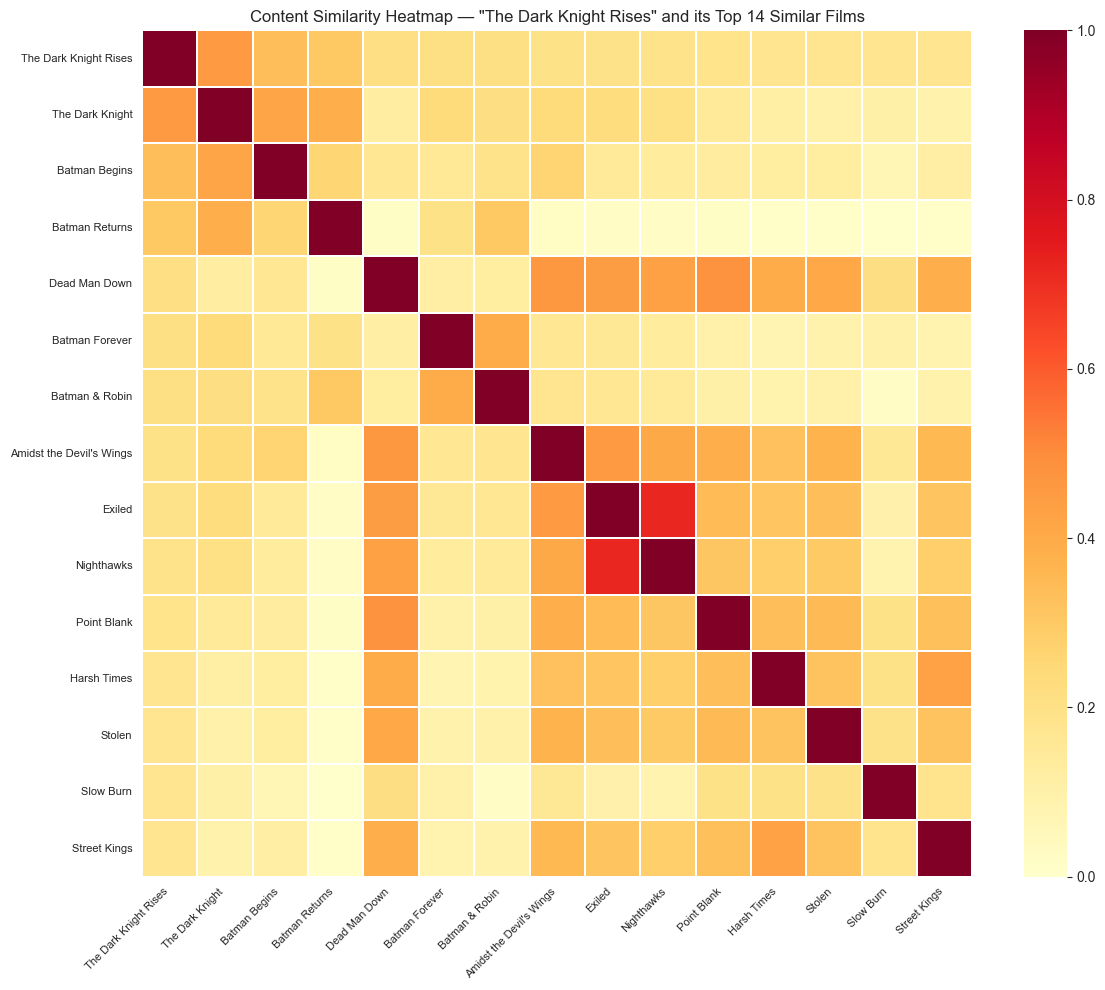

In [30]:
def plot_similarity_heatmap(movie_title: str, top_n: int = 15):
    """Plot cosine similarity heatmap between a movie and its top-N similar movies."""
    match = next((t for t in title_to_idx.index if movie_title.lower() in t.lower()), None)
    if not match:
        print(f"'{movie_title}' not found.")
        return

    idx = title_to_idx[match]
    sims = cosine_sim[idx]
    top_idx = np.argsort(sims)[::-1][1:top_n+1]
    top_titles = df.iloc[top_idx]['title'].tolist()
    all_titles = [match] + top_titles
    all_idx    = [idx]   + list(top_idx)

    sub_matrix = cosine_sim[np.ix_(all_idx, all_idx)]

    plt.figure(figsize=(12, 10))
    sns.heatmap(
        sub_matrix,
        xticklabels=[t[:25] for t in all_titles],
        yticklabels=[t[:25] for t in all_titles],
        cmap='YlOrRd', annot=False, linewidths=0.3
    )
    plt.title(f'Content Similarity Heatmap — "{match}" and its Top {top_n} Similar Films',
              fontsize=12)
    plt.xticks(rotation=45, ha='right', fontsize=8)
    plt.yticks(fontsize=8)
    plt.tight_layout()
    plt.show()


plot_similarity_heatmap('The Dark Knight', top_n=14)

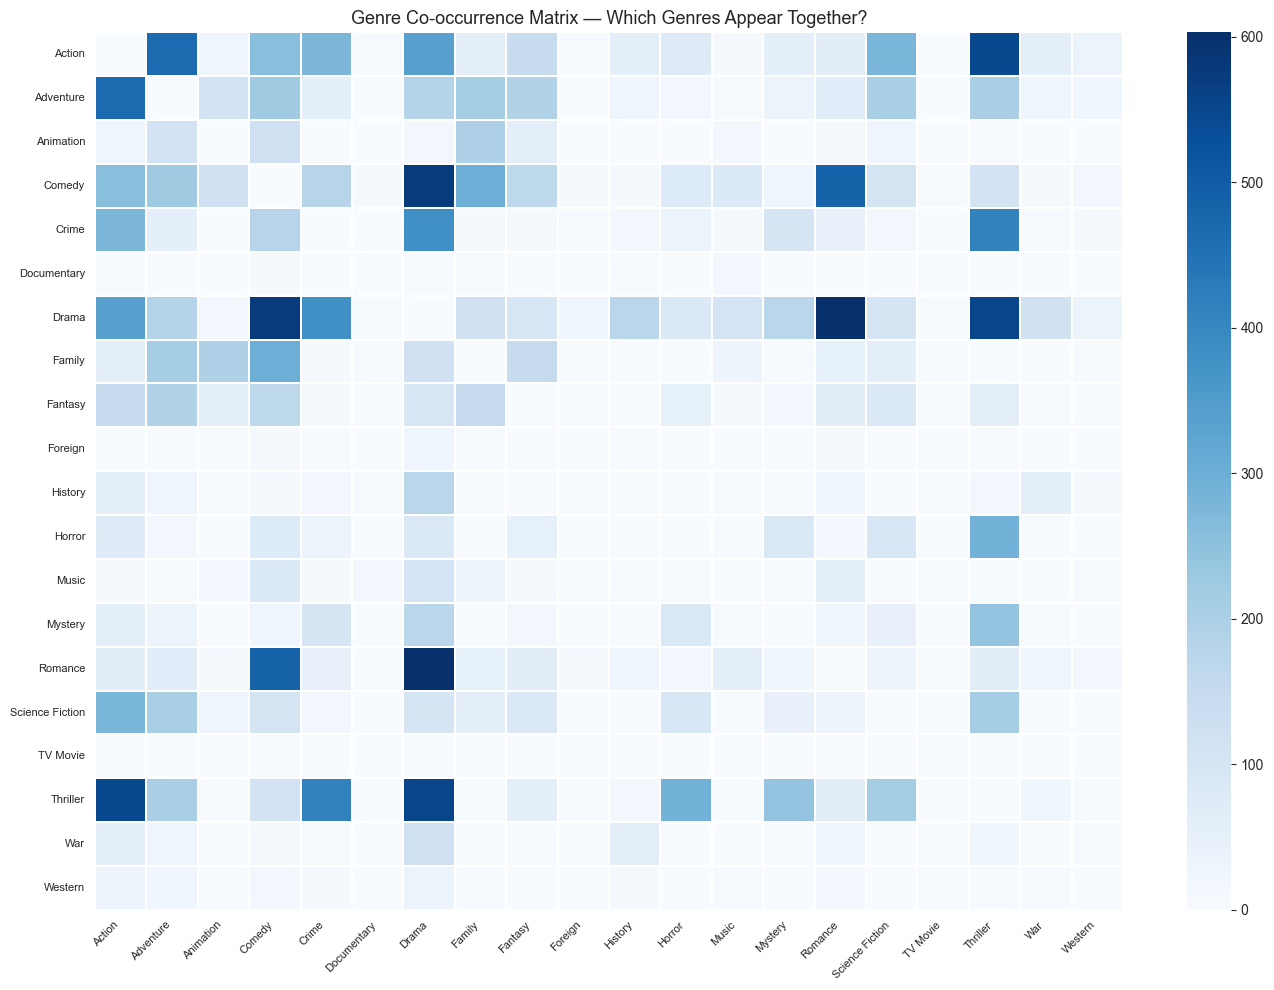

In [31]:
# Genre co-occurrence heatmap — which genres appear together most often?
unique_genres = sorted(set(g for row in df['genres_list'] for g in row))
cooccur = np.zeros((len(unique_genres), len(unique_genres)), dtype=int)

genre_to_i = {g: i for i, g in enumerate(unique_genres)}

for genres in df['genres_list']:
    for g1 in genres:
        for g2 in genres:
            if g1 != g2:
                cooccur[genre_to_i[g1]][genre_to_i[g2]] += 1

plt.figure(figsize=(14, 10))
sns.heatmap(
    cooccur, xticklabels=unique_genres, yticklabels=unique_genres,
    cmap='Blues', linewidths=0.2, fmt='d',
    annot=True if len(unique_genres) < 15 else False
)
plt.title('Genre Co-occurrence Matrix — Which Genres Appear Together?', fontsize=13)
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

## Summary

| Step | What we built |
|------|---------------|
| 1–3 | Loaded and merged TMDB 5000 movies + credits; parsed JSON columns; built soup feature |
| 4 | EDA — genre distribution, rating distribution, release year, most-voted movies |
| 5 | Bayesian weighted rating (IMDb formula) to penalise low-vote movies |
| 6 | **Engine 1** - Collaborative filtering via `corrwith()` on simulated user-movie matrix |
| 7 | **Engine 2** - Content-based filtering with TF-IDF + cosine similarity on soup |
| 8 | **Engine 3** - Emotion-based recommendation: NLP mood detection + genre mapping (no scraping) |
| 9 | **Engine 4** - Hybrid: content similarity + mood match + quality score (weighted) |
| 10 | Interactive ipywidgets UI with engine selector, mood presets, and year filter |
| 11 | Similarity heatmap + genre co-occurrence matrix |


### Which Engine to Use?

```
"I loved Inception, show me similar movies"          →  Engine 2 (Content)
"Users who liked The Dark Knight also liked…"        →  Engine 1 (Collaborative)  
"I'm feeling sad tonight, what should I watch?"      →  Engine 3 (Emotion)
"I liked Interstellar and I feel adventurous"        →  Engine 4 (Hybrid) ← best results
```

### Potential Improvements
- **Matrix Factorization (SVD)** - more powerful collaborative filtering using `surprise` library
- **BERT sentence embeddings** = replace TF-IDF with transformer-based semantic similarity
- **Real user ratings** - replace simulated matrix with MovieLens 25M (25 million real ratings)
- **Real-time mood detection** - use a sentiment analysis model (`transformers` pipeline) instead of keyword matching
- **Poster thumbnails** - use TMDB API to fetch movie poster images and display in the widget